# ATRIM · Soustraction de fond en fluoroscopie

**Compte rendu du TP — Florian et Hugo**

L’objectif est de faire ressortir les instruments sur une séquence de neurointervention. Nous segmentons d’abord les instruments visibles et comparons les masques aux annotations du TP. Dans un second temps, nous isolons les nouvelles détections pour visualiser le déplacement de la pointe du guidewire.

Nous utilisons `frame_201.png` comme image de fond pour la segmentation complète. Les résultats concernent les neuf images 211 à 291. L’énoncé est disponible dans [le notebook du TP](TP5-background-substraction-sv.ipynb).

In [ ]:
from pathlib import Path
from IPython.display import Image, display

RESULTS = Path("results")

def afficher(nom, largeur=None):
    chemin = RESULTS / nom
    if not chemin.is_file():
        raise FileNotFoundError(
            f"{chemin} introuvable. Ouvrir le notebook à la racine du projet "
            "et générer les résultats avec main.py."
        )
    largeur = largeur or (850 if "comparaison_" in chemin.name or "etapes_" in chemin.name else 512)
    display(Image(filename=str(chemin), width=largeur))

## 1. Essais intermédiaires

Chaque planche montre l’image ou le masque à la sortie de l’opération étudiée. Nous choisissons les réglages en observant le grain du fond, la visibilité du tracé et sa continuité. La validation du pipeline complet est présentée en partie 2.

### 1.1 Vue d’ensemble du pipeline

La radiographie courante et l’image 201 alimentent une chaîne commune. Après filtrage, seuillage, élimination des composantes de moins de **300 pixels** et fermeture, nous excluons trois zones de bord puis partageons le masque à la **ligne 348** sur les images de 512 lignes. Le guidewire occupe la zone haute et le microcathéter la zone basse.

```mermaid
flowchart TD
    I["Radiographie courante"] --> D["Soustraction avec la référence fixe 201"]
    D --> F["Filtres, seuillage et composantes d’au moins 300 pixels"]
    F --> K["Fermeture elliptique 3×3"]
    K --> B["Exclusion des trois zones de bord"]
    B --> S["Coupe horizontale à la ligne 348"]
    S -->|"y < 348"| G["Masque haut : guidewire"]
    S -->|"y ≥ 348"| C["Masque bas : microcathéter"]
    G --> O["Superposition des deux masques sur la radiographie"]
    C --> O
    classDef catheter fill:#e7f4ea,stroke:#538663,color:#173f28
    classDef guidewire fill:#faeeed,stroke:#b7716e,color:#6f2621
    class C catheter
    class G guidewire
```

### 1.2 Délimitation entre le guidewire et le microcathéter

Les deux annotations TIFF montrent la position relative des instruments. Sur l’image 291, `291_GuideWire.tiff` suit la longue courbe supérieure et sa boucle. `291_MicroCath.tiff` suit le segment qui descend à droite. La planche superpose ces tracés à la radiographie.

Sur les TIFF bruts de 211 à 291, la ligne 348 place les 3 340 pixels GuideWire au-dessus et 1 463 des 1 577 pixels MicroCath au-dessous ou sur la ligne (92,8 %). La coupure a été choisie sur la même séquence que celle évaluée.

Nous appliquons la coupe **après la fermeture et l’exclusion des zones de bord**, avec les lignes $y < 348$ attribuées au guidewire et les lignes $y \geq 348$ au microcathéter. La coordonnée $y$ croît du haut vers le bas et commence à zéro. La ligne est redimensionnée en proportion de la hauteur de l’image. Le programme utilise ensuite cette même séparation pour toute la séquence. Les TIFF servent à choisir la ligne et à évaluer les résultats, sur la même séquence. Cette comparaison porte ainsi sur la séquence qui a servi à choisir la coupe.

[Code de la séparation géométrique](separation_outils.py)

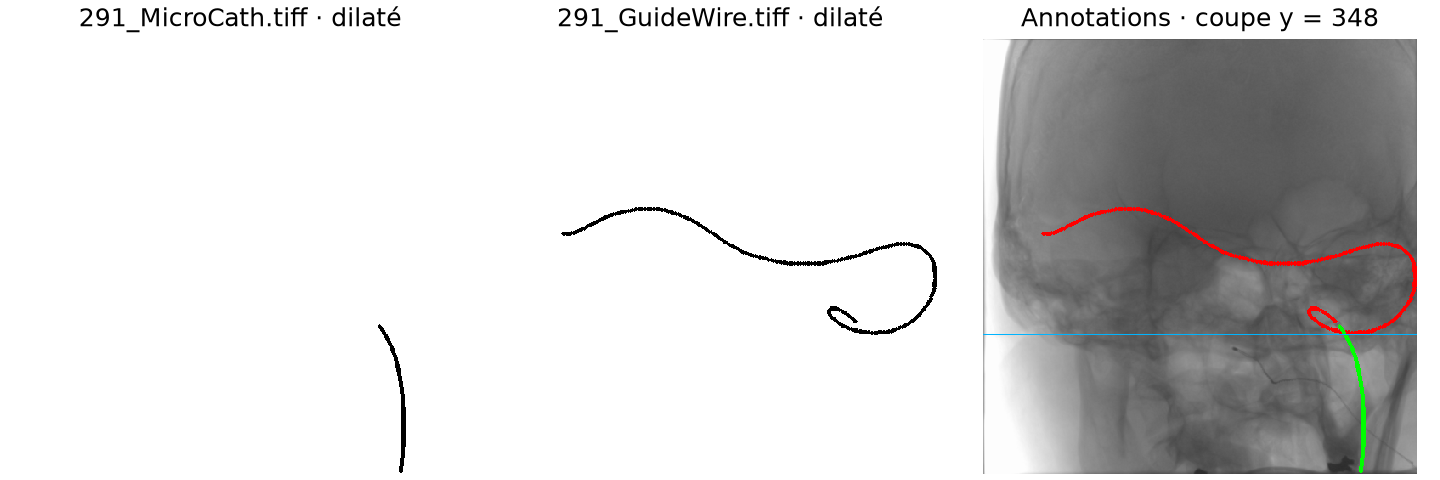

In [ ]:
afficher('validation_par_outil/annotations_291.png', largeur=900)

### 1.3 Soustraction de l’image de référence

**Entrée.** Pour chaque image (I_k), nous prenons `frame_201.png` comme fond fixe. Nous calculons (D_k=I_{201}-I_k) en flottants. Un pixel devenu plus sombre donne une différence positive.

```python
difference = reference.astype(np.float32) - image.astype(np.float32)
```

À gauche, la radiographie 211. À droite, la différence $I_{201}-I_{211}$, avec le zéro en gris moyen. Les structures immobiles devraient s’atténuer. Tout déplacement du patient ou changement d’intensité peut cependant laisser une trace dans la différence.

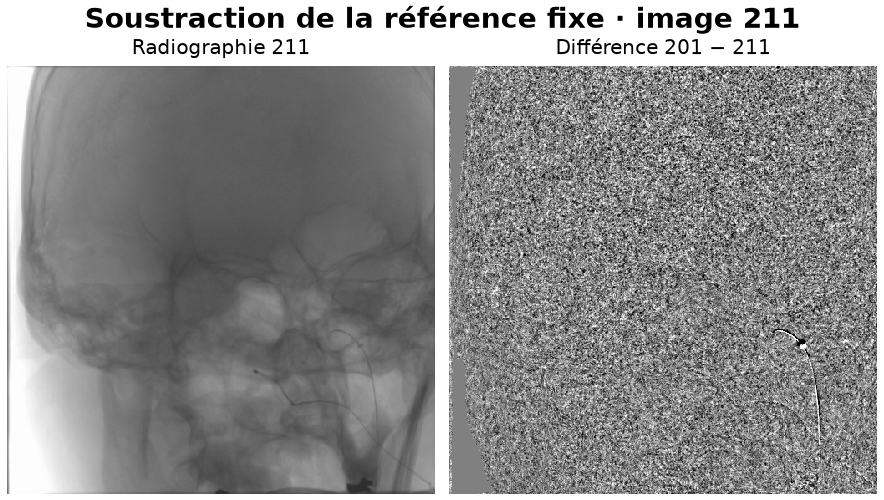

In [ ]:
afficher('intermediaires/comparaisons_filtres/difference.png', largeur=900)

La soustraction atténue les structures visibles dans les deux radiographies. Sur 211, elle fait apparaître une réponse claire et sombre autour du tracé à droite, avec du grain dans le fond. Ce grain motive le filtrage spatial suivant.

### 1.4 Filtrage spatial : gaussien, médian et bilatéral

**Entrée.** Nous partons de la même différence signée dans les quatre essais. Le gaussien moyenne les voisins, le médian remplace le pixel par la médiane locale, et le bilatéral pondère aussi selon l’écart d’intensité pour limiter le lissage à travers les contours.

```python
gaussien = cv2.GaussianBlur(difference, (5, 5), 1)
median = cv2.medianBlur(difference, 5)
sigma_couleur = 50 * float(np.ptp(difference)) / 255
bilateral = cv2.bilateralFilter(difference, 5, sigma_couleur, 50)
```

Le paramètre d’intensité 50 du premier essai sur une échelle 0–255 est converti dans l’échelle de la différence signée. La figure reprend la différence 201 − 291. Les quatre vues utilisent la même échelle de gris.

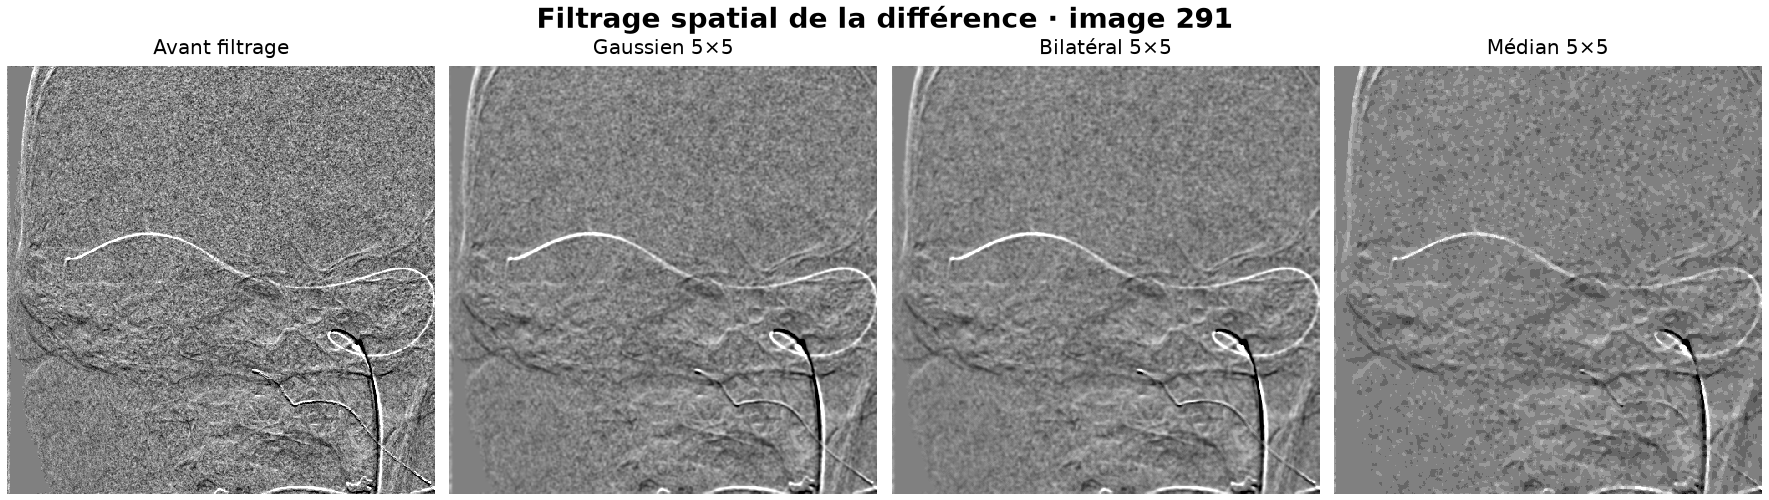

In [ ]:
afficher('intermediaires/comparaisons_filtres/spatial.png', largeur=900)

Le gaussien et le bilatéral atténuent le grain tout en laissant visible le tracé fin sur 291. Le médian laisse des aplats irréguliers et estompe certaines portions du tracé. Les sorties du gaussien et du bilatéral sont visuellement proches. Nous gardons le gaussien pour son lissage régulier.

### 1.5 Filtrage spectral : passe-haut ou passe-bande

**Entrée.** Nous conservons le gaussien spatial, puis comparons l’image sans filtrage de Fourier, un passe-haut gaussien, un passe-haut de Butterworth ((D_0=12), ordre 2) et le passe-bande gaussien. Le passe-haut atténue les variations lentes. Le passe-bande combine cette atténuation avec un passe-bas pour limiter les hautes fréquences résiduelles.

```python
passe_haut = 1 - np.exp(-distance2 / (2 * 10**2))
passe_bas = np.exp(-distance2 / (2 * 60**2))
passe_bande = passe_haut * passe_bas
```

Le masque fréquentiel multiplie la transformée centrée. La transformée inverse ramène la réponse dans le domaine spatial.

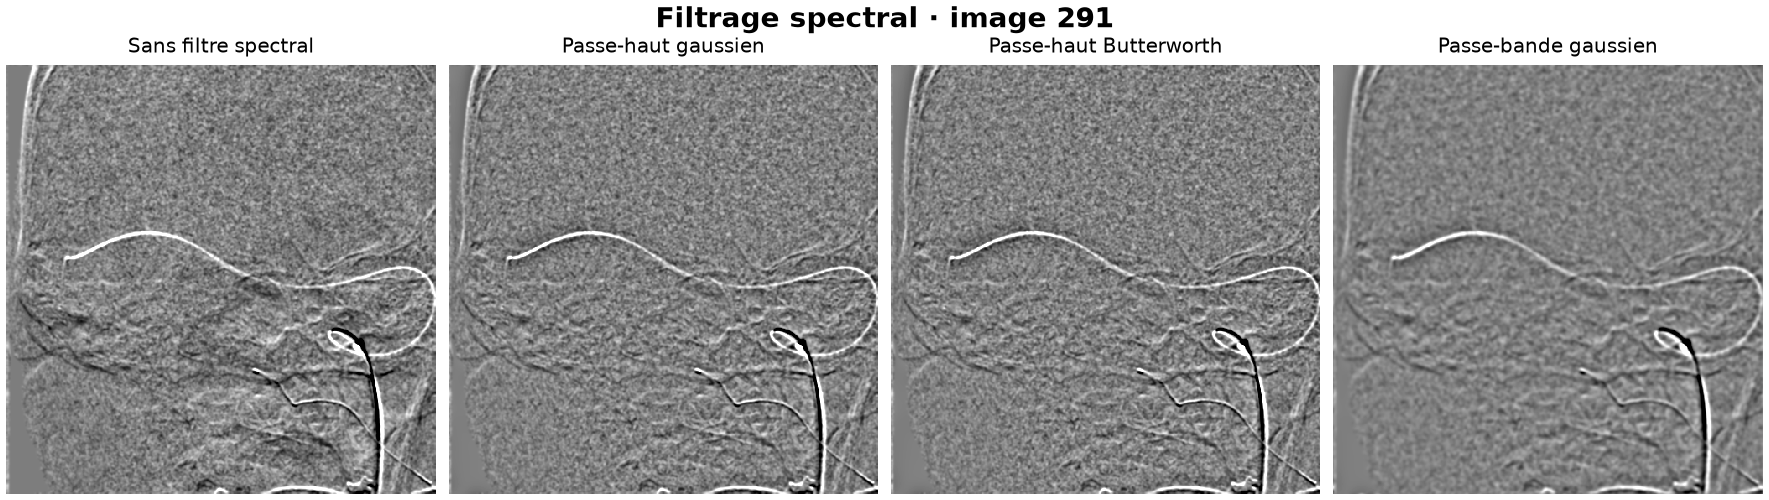

In [ ]:
afficher('intermediaires/comparaisons_filtres/spectral.png', largeur=900)

Les deux passe-haut laissent du grain autour du tracé. Le passe-bande l’atténue davantage, et la courbe reste visible sur une grande partie de l’image. Nous gardons cette réponse pour la transformation d’histogramme.

### 1.6 Transformation d’histogramme : maximum ou percentile

**Entrée.** À la sortie du passe-bande, nous gardons les valeurs positives. Nous comparons un étirement jusqu’au maximum avec un étirement jusqu’au **99ᵉ percentile**. Les deux donnent une image 8 bits, mais avec le percentile, les valeurs au-dessus de cette borne saturent. Le reste de l’image exploite alors davantage la plage 0–255.

```python
positive = np.maximum(filtree, 0)
limite = np.percentile(positive, 99)
contraste = np.rint(255 * np.clip(positive / limite, 0, 1))
```

Le code complet protège le cas où la limite vaut zéro. Les deux cartes de contraste sont affichées sur la même échelle 0–255, directement après l’étirement.

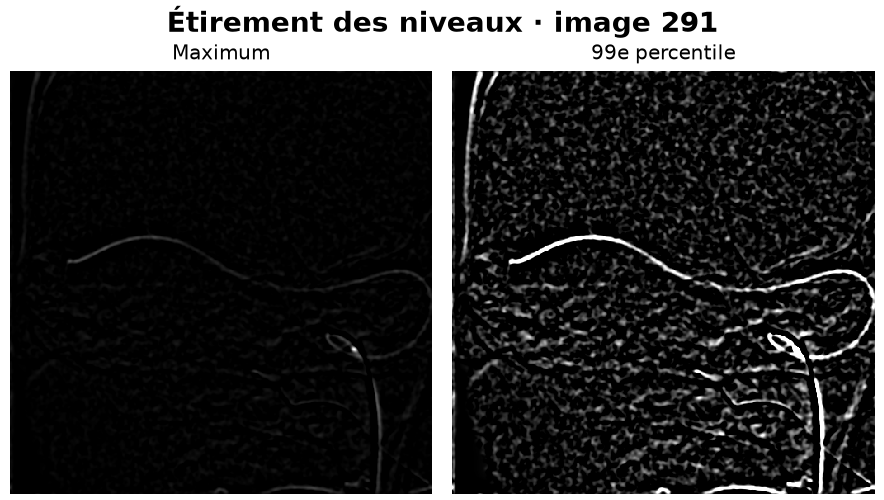

In [ ]:
afficher('intermediaires/comparaisons_filtres/histogramme.png', largeur=900)

L’étirement jusqu’au maximum donne une image sombre où une partie du tracé se distingue difficilement. Avec le 99ᵉ percentile, le tracé devient plus lumineux et plus facile à suivre. Des détails du fond ressortent aussi. Nous gardons le percentile pour rendre visibles les portions faibles avant le seuillage.

### 1.7 Segmentation : choix du seuil

**Entrée.** Nous partons de la même carte de contraste. Otsu propose une coupure automatique. Nous testons plusieurs décalages positifs en unités de gris, ce qui demande une réponse plus forte avant de classer le pixel comme outil.

```python
otsu, _ = cv2.threshold(contraste, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
outil = contraste > min(otsu + 30, 255)
```

Les quatre masques montrent le résultat immédiat du seuillage, avant la morphologie.

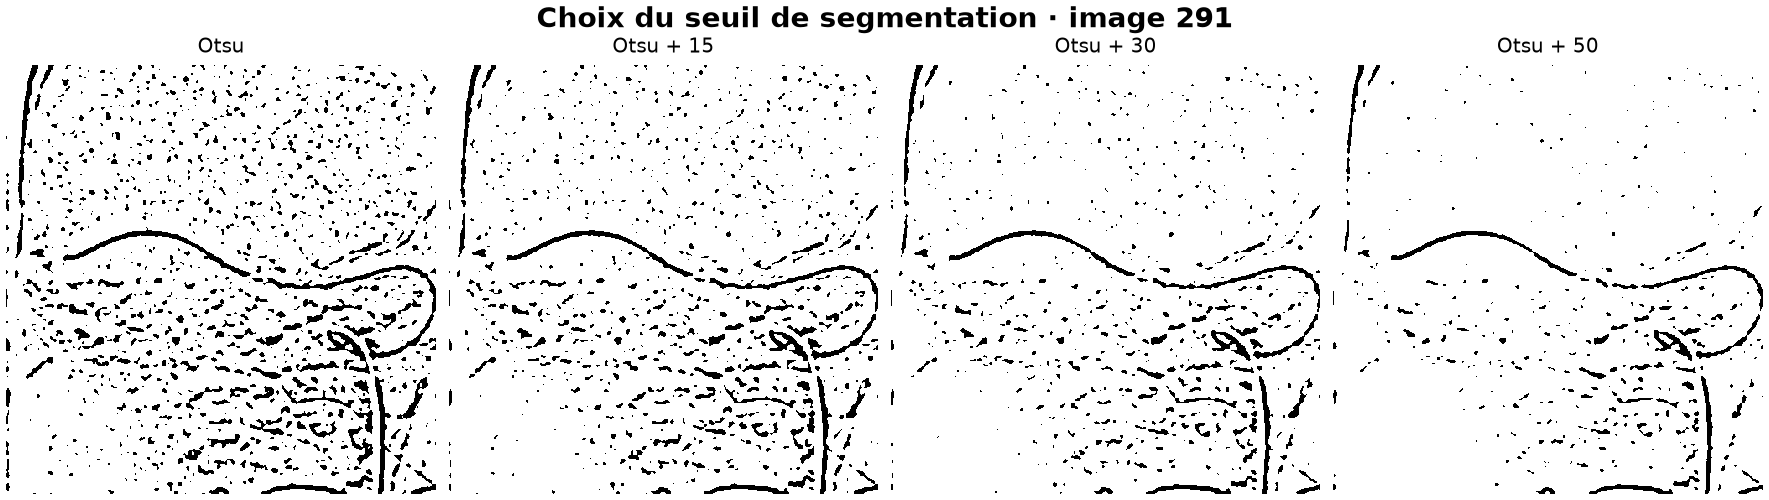

In [ ]:
afficher('intermediaires/comparaisons_filtres/segmentation.png', largeur=900)

Avec Otsu seul, beaucoup de points noirs se répartissent dans le fond. Quand le seuil augmente, ces points diminuent et certaines portions fines du tracé s’interrompent. Nous gardons Otsu + 30 pour préserver la continuité du tracé tout en retirant une partie des points isolés.

### 1.8 Morphologie : composantes connexes et fermeture
    
Nous partons du masque d’Otsu + 30. Chaque composante connexe (8-connexité) est un groupe de pixels noirs reliés entre eux. Nous comparons six aires minimales, de 20 à 500 pixels, pour voir quelles parties du tracé subsistent quand on écarte les petites composantes.

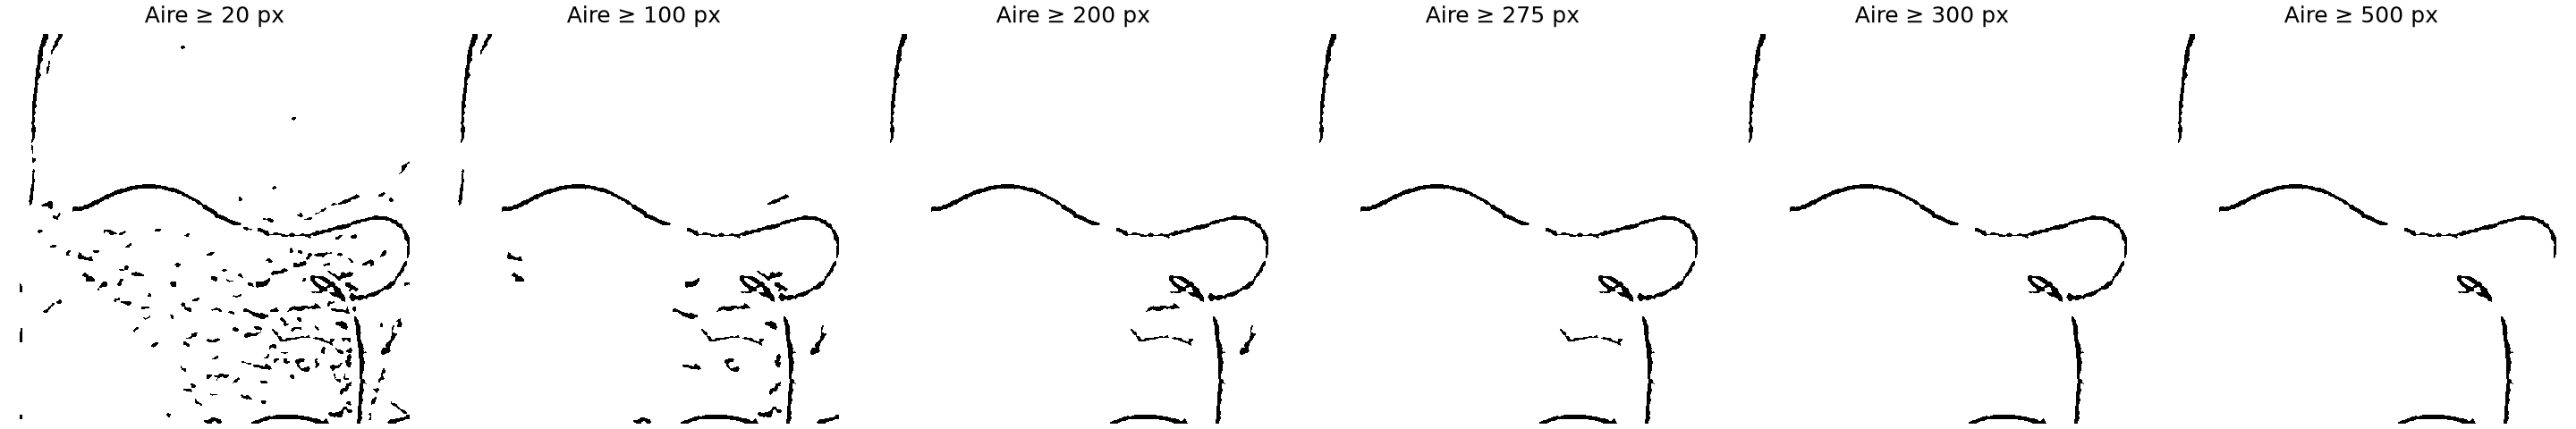

In [ ]:
afficher('intermediaires/aires_composantes/aires_291.png', largeur=1100)

Sur 291, passer de 20 à **300 pixels** retire de nombreuses taches et quelques fragments autour du fil. La boucle de droite est encore visible à 300 pixels. À 500 pixels, une partie de son retour disparaît. Nous retenons donc **300 pixels d’aire minimale** avant la fermeture.

La planche suivante compare la sélection par aire et les fermetures 3×3 et 5×5.

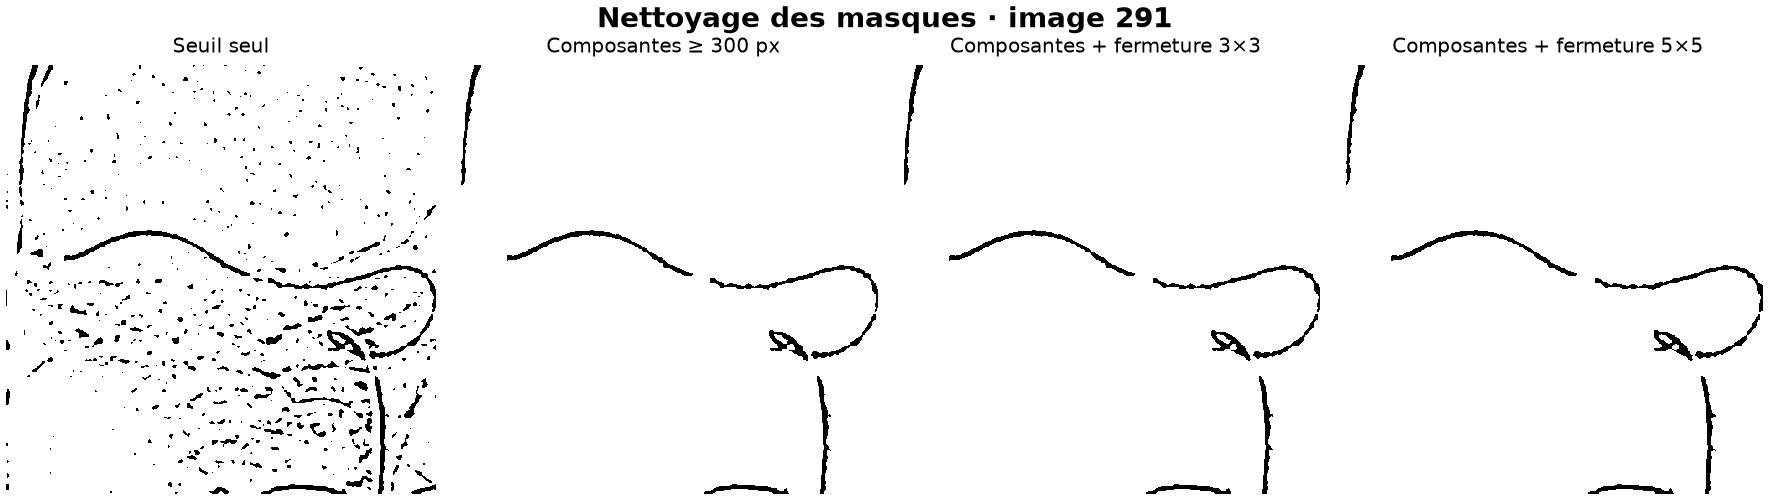

In [ ]:
afficher('intermediaires/comparaisons_filtres/morphologie.png', largeur=900)

Après la sélection des composantes de 300 pixels ou plus, la fermeture comble de petites coupures. Nous gardons le noyau elliptique **3×3** pour limiter l’élargissement des fragments par rapport au 5×5.

### Exclusion de trois zones de bord

Après la fermeture, nous supprimons les détections dans trois rectangles fixes, repérés sur les superpositions de la séquence :

- **En haut à gauche** : $x < 45$ et $y < 240$, où le bord du crâne apparaît en rouge.
- **En bas** : $290 \leq x < 438$ et $y \geq 485$, où une bande horizontale apparaît en vert.
- **En bas à droite** : $x \geq 456$ et $y \geq 348$, où le masque vert suit par endroits le bord de l’image.

Ces coordonnées s’appliquent aux images de 512 × 512 pixels et sont redimensionnées pour les autres dimensions. La bande inférieure s’arrête à gauche du tracé descendant du microcathéter. Le rectangle inférieur droit commence à droite de ce tracé. Sur les images 201 à 291, les trois rectangles ne recouvrent aucun pixel des annotations TIFF dilatées. [Code du masque spatial](separation_outils.py)

La rangée du haut montre les détections avant nettoyage, avec les trois rectangles à exclure en **bleu**. La rangée du bas montre les mêmes radiographies après suppression des pixels dans ces zones. C’est la dernière étape de nettoyage du masque, juste avant la séparation des outils.

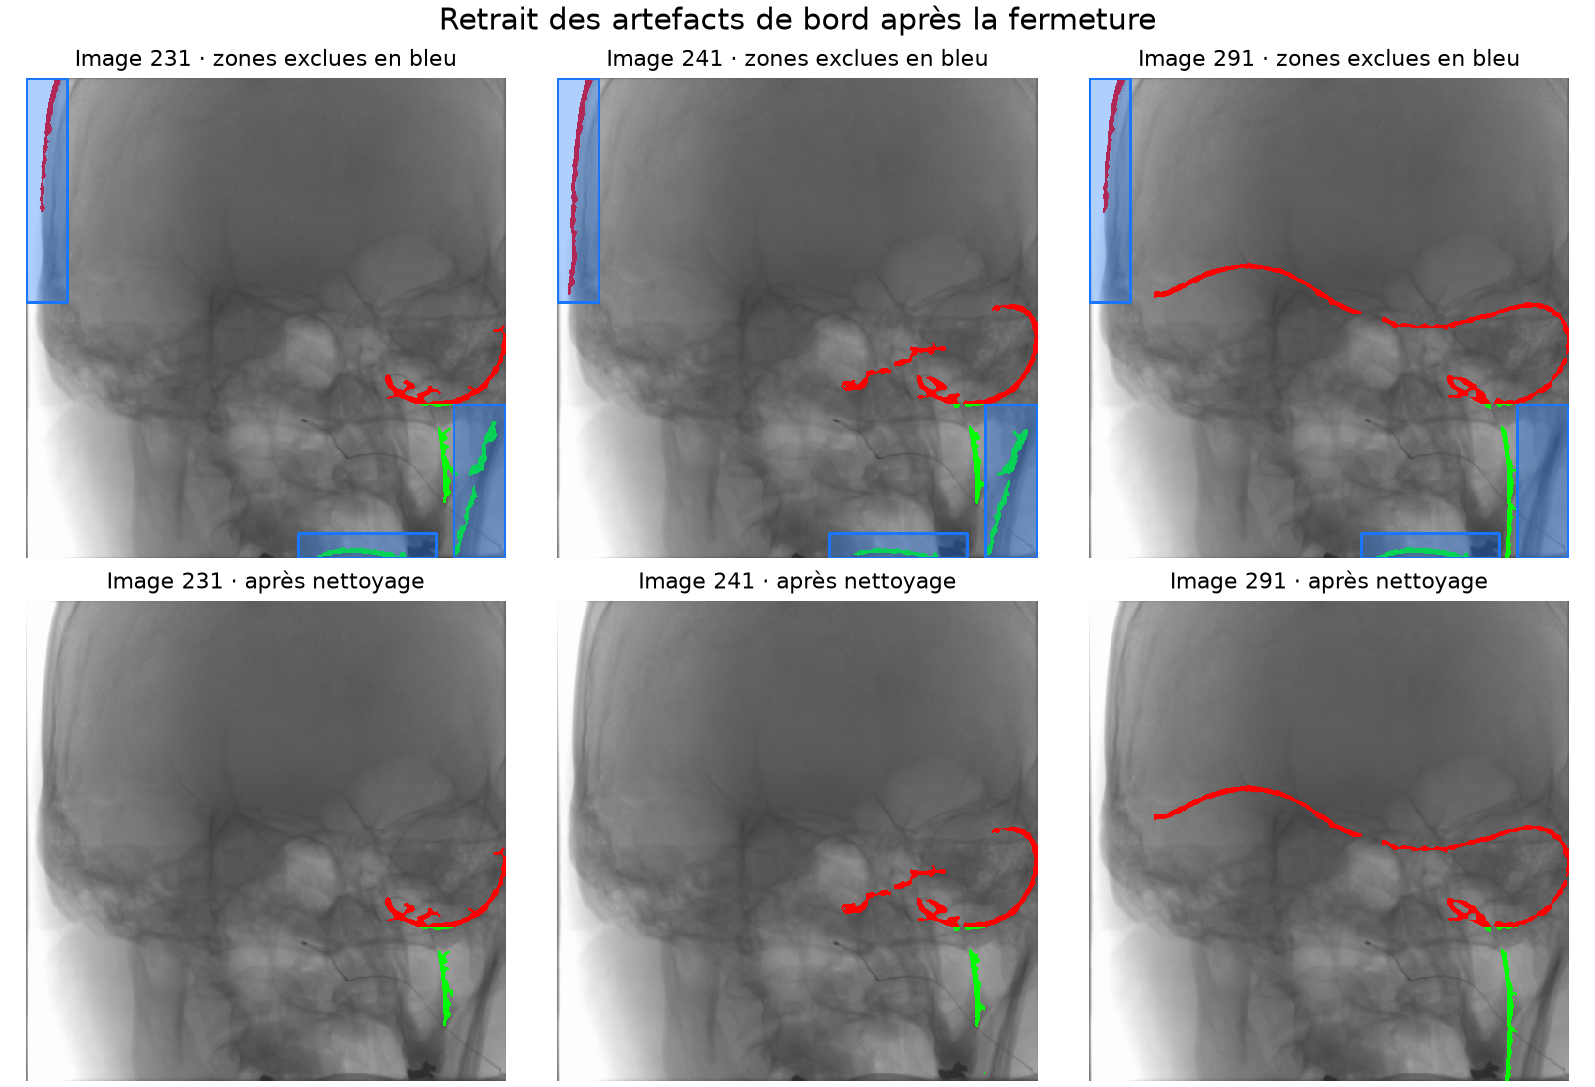

In [ ]:
from io import BytesIO

import cv2
import matplotlib.pyplot as plt
import numpy as np

from segmentation import lire_image, segmenter_outil
from separation_outils import separer_outils, zone_sans_artefacts
from visualisation import superposer

donnees = Path("catheter")
reference = lire_image(donnees / "frame_201.png")
numeros = (231, 241, 291)
fig, axes = plt.subplots(2, 3, figsize=(11, 7.5), layout="constrained")
fig.suptitle("Retrait des artefacts de bord après la fermeture", fontsize=15)

for colonne, numero in enumerate(numeros):
    image = lire_image(donnees / f"frame_{numero}.png")
    _, masque_ferme = segmenter_outil(reference, image)
    zone = zone_sans_artefacts(image.shape)

    # Couleurs provisoires pour voir les détections à enlever sous le bleu.
    avant = cv2.cvtColor(superposer(image, *separer_outils(masque_ferme)), cv2.COLOR_BGR2RGB)
    bleu = np.array([25, 119, 255], dtype=np.float32)
    avant[~zone] = np.rint(0.66 * avant[~zone] + 0.34 * bleu).astype(np.uint8)
    contours, _ = cv2.findContours((~zone).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(avant, contours, -1, (25, 119, 255), 2)

    apres = cv2.cvtColor(superposer(image, *separer_outils(masque_ferme & zone)), cv2.COLOR_BGR2RGB)
    for rang, (vue, titre) in enumerate((
        (avant, f"Image {numero} · zones exclues en bleu"),
        (apres, f"Image {numero} · après nettoyage"),
    )):
        axe = axes[rang, colonne]
        axe.imshow(vue, interpolation="nearest")
        axe.set_title(titre, fontsize=11)
        axe.axis("off")

tampon = BytesIO()
fig.savefig(tampon, format="png", dpi=145)
plt.close(fig)
display(Image(data=tampon.getvalue(), format="png", width=900))

## 2. Pipeline retenu pour le masque complet

Le code ci-dessous est extrait de [`segmentation.py`](segmentation.py). La même chaîne et les mêmes paramètres sont utilisés pour les neuf images. Le masque booléen interne marque l’outil avec `True`. À l’export, l’outil est noir (0) et le fond blanc (255 dans le PNG, soit 1 en binaire).


```python
AIRE_MINIMALE_COMPOSANTE = 300


def filtrer(reference, image):
    if reference.shape != image.shape:
        raise ValueError("Les deux images doivent avoir les mêmes dimensions.")

    difference = reference.astype(np.float32) - image.astype(np.float32)
    gauss = cv2.GaussianBlur(difference, (5, 5), 1)

    hauteur, largeur = gauss.shape
    y, x = np.ogrid[:hauteur, :largeur]
    distance2 = (y - hauteur // 2)**2 + (x - largeur // 2)**2
    passe_haut = 1 - np.exp(-distance2 / (2 * 10**2))
    passe_bas = np.exp(-distance2 / (2 * 60**2))
    passe_bande = (passe_haut * passe_bas).astype(np.float32)

    spectre = np.fft.fftshift(cv2.dft(gauss, flags=cv2.DFT_COMPLEX_OUTPUT), axes=(0, 1))
    spectre_filtre = np.fft.ifftshift(spectre * passe_bande[:, :, None], axes=(0, 1))
    filtree = cv2.idft(spectre_filtre, flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT)

    return difference, gauss, filtree


def segmenter_outil(reference, image):
    """Renvoie la réponse de chaque filtre et les masques de la chaîne complète."""
    difference, gauss, filtree = filtrer(reference, image)
    positive = np.maximum(filtree, 0)
    limite = np.percentile(positive, 99)
    contraste = np.zeros_like(positive, dtype=np.uint8)
    if limite > 0:
        contraste = np.rint(255 * np.clip(positive / limite, 0, 1)).astype(np.uint8)

    otsu, _ = cv2.threshold(contraste, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    outil = (contraste > min(otsu + 30, 255)).astype(np.uint8)
    _, etiquettes, stats, _ = cv2.connectedComponentsWithStats(outil, connectivity=8)
    garder = stats[:, cv2.CC_STAT_AREA] >= AIRE_MINIMALE_COMPOSANTE
    garder[0] = False
    composantes = garder[etiquettes].astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    masque = cv2.morphologyEx(composantes, cv2.MORPH_CLOSE, noyau).astype(bool)
    return {
        "Soustraction": difference,
        "Filtrage spatial": gauss,
        "Filtrage spectral": filtree,
        "Contraste au percentile 99": contraste,
        "Otsu + 30": 1 - outil,
        f"Composantes ≥ {AIRE_MINIMALE_COMPOSANTE} px": 1 - composantes,
        "Fermeture 3×3": ~masque,
    }, masque
```

### Référence manuelle et métriques

Pour chaque image (k), nous faisons l’union des pixels d’outil dans `k_MicroCath.tiff` et `k_GuideWire.tiff`. Nous dilatons cette union avec un disque de rayon 2 pixels pour tenir compte de l’imprécision du tracé manuel.

Sur les masques binaires (M) et (G), le **SAD** compte les pixels différents. La **MSE** est la proportion de pixels différents, car une erreur binaire vaut 1 au carré. Le **PSNR** vaut (-10log_{10}(mathrm{MSE})) en dB, puisque le pic vaut 1. Un masque identique à la référence donne un PSNR infini.


```python
def annotation_manuelle(dossier: Path, numero: int):
    microcatheter = lire_image(dossier / f"{numero}_MicroCath.tiff") == 0
    guide = lire_image(dossier / f"{numero}_GuideWire.tiff") == 0
    return dilation(microcatheter | guide, disk(2))

def mesurer(estimation, annotation):
    """Calcule les erreurs sur les masques binaires avec un pic égal à 1."""
    if estimation.shape != annotation.shape:
        raise ValueError("Les masques comparés doivent avoir les mêmes dimensions.")
    erreurs = estimation != annotation
    sad = int(erreurs.sum())
    mse = float(erreurs.mean())
    psnr = float(-10 * np.log10(mse)) if mse else float("inf")
    return sad, mse, psnr
```

### Validation quantitative

| Image | SAD (pixels) | MSE | PSNR (dB) |
|---:|---:|---:|---:|
| 211 | 1 071 | 0,004086 | 23,89 |
| 221 | 1 165 | 0,004444 | 23,52 |
| 231 | 1 796 | 0,006851 | 21,64 |
| 241 | 2 344 | 0,008942 | 20,49 |
| 251 | 1 696 | 0,006470 | 21,89 |
| 261 | 1 773 | 0,006763 | 21,70 |
| 271 | 1 365 | 0,005207 | 22,83 |
| 281 | 1 355 | 0,005169 | 22,87 |
| 291 | 1 823 | 0,006954 | 21,58 |

| Mesure | Moyenne | Écart-type |
|---|---:|---:|
| SAD | 1 598,7 | 374,9 |
| MSE | 0,006098 | 0,001430 |
| PSNR (dB) | 22,27 | 1,02 |

Le SAD est maximal sur **241** (2 344 pixels) et minimal sur **211** (1 071 pixels). Sur **291**, il vaut **1 823 pixels**. Les planches situent les erreurs dans l’image. [CSV détaillé](results/validation/scores.csv)

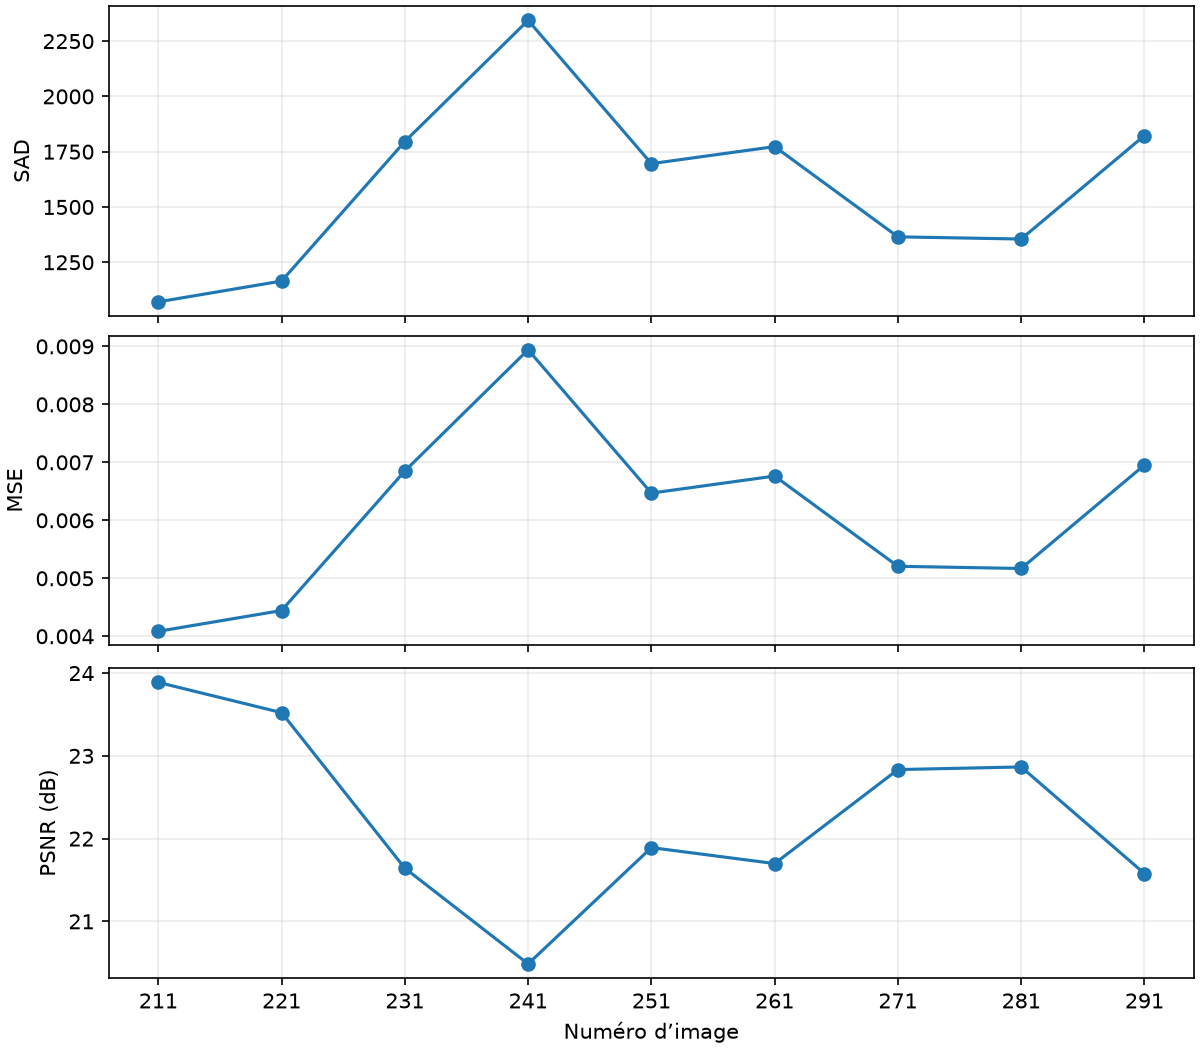

In [ ]:
afficher('validation/scores.png')

### Validation qualitative du masque complet

Chaque planche présente le masque estimé, l’annotation complète dilatée et la superposition verte sur la radiographie dont le contraste est rehaussé par CLAHE. Nous montrons ici l’image avec le plus grand SAD, celle avec le plus petit, et la dernière. Après le nettoyage des bords, des contours du fond et des coupures du tracé subsistent. [Les neuf planches](results/validation/)

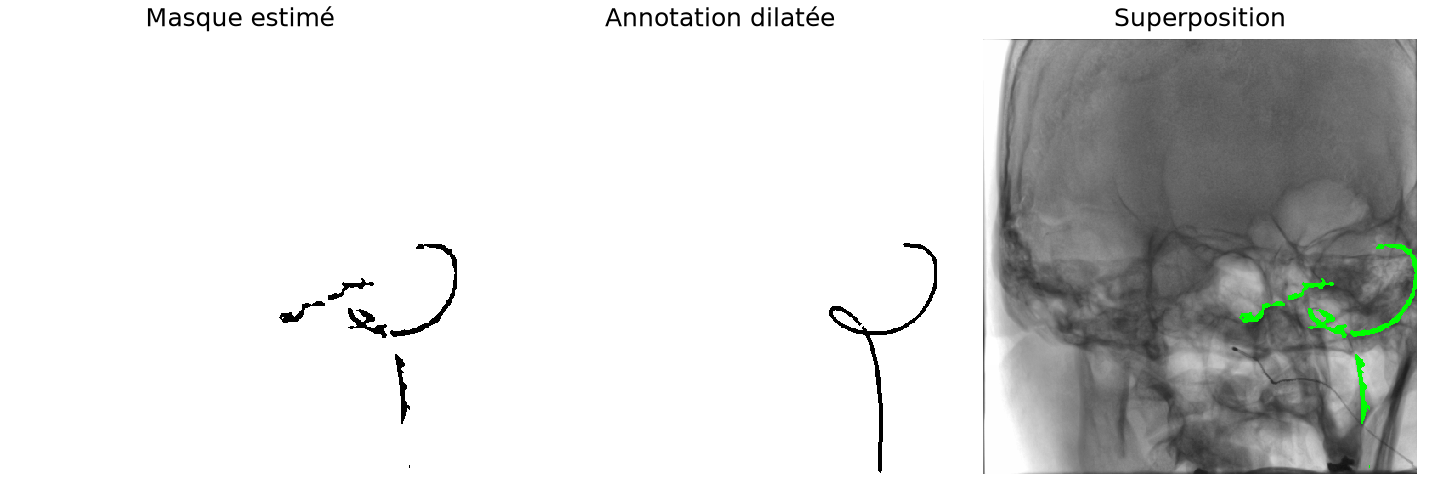

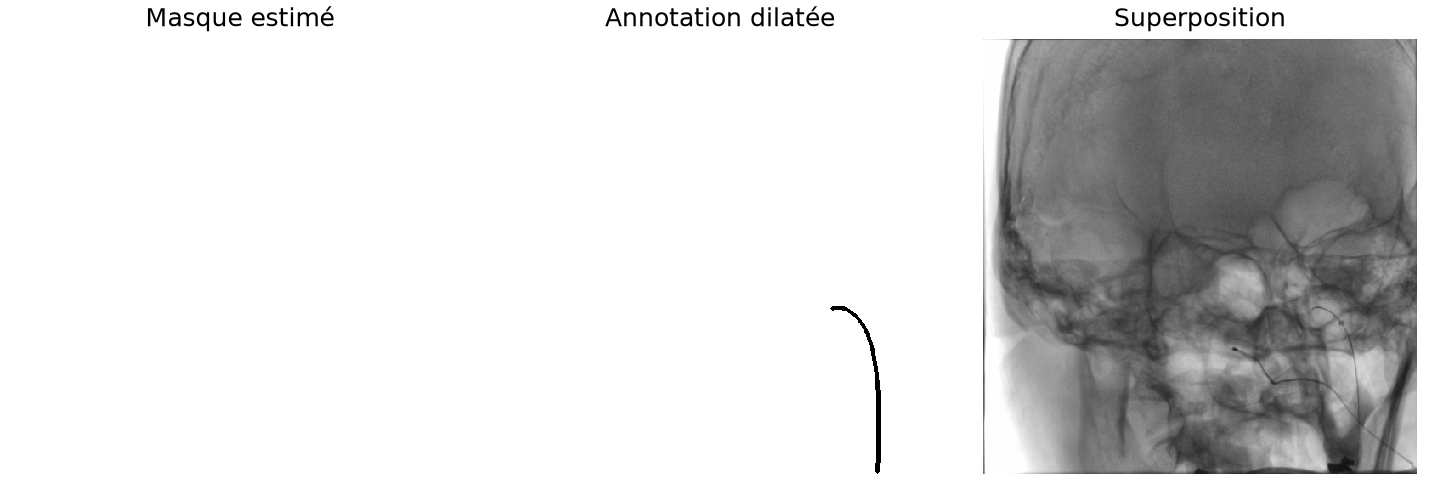

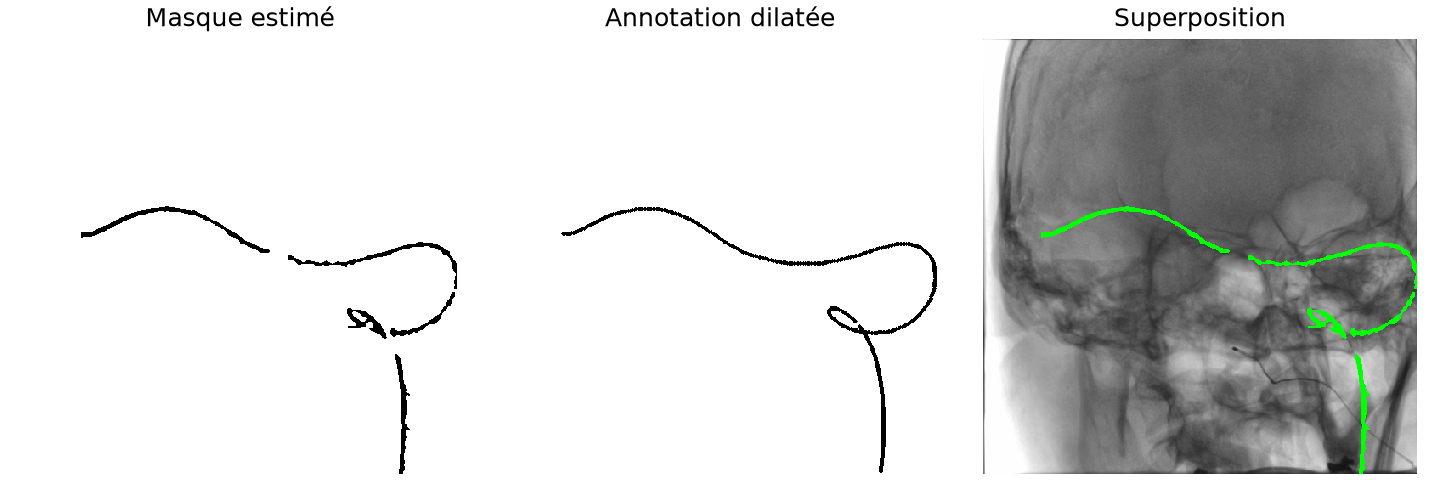

In [ ]:
afficher('validation/comparaison_241.png')
afficher('validation/comparaison_211.png')
afficher('validation/comparaison_291.png')

## 3. Pour aller plus loin — Isoler la pointe et reconstruire le trajet du guidewire

Le guidewire est le long fil courbé qui se déplace dans la zone haute. Pour suivre ses nouvelles portions, nous remplaçons la référence fixe par l’image précédente et conservons les détections au-dessus de la même ligne de séparation. Le masque à référence fixe en haut sur 211, 251 et 291 donne le point de départ de cette comparaison.


### 3.1 Isoler la pointe par différences successives

Nous soustrayons l’image courante à la précédente, de $I_{201}-I_{211}$ à $I_{281}-I_{291}$. Le double seuil exploite les changements de la réponse filtrée, et l’historique élimine les pixels déjà détectés. Nous conservons la zone haute en excluant le bord supérieur gauche. Une érosion avec le motif 5×5 sélectionné puis une dilatation en croix 3×3 nettoient les détections. La superposition des nouvelles portions est **rouge**.

```python
def suivre_pointe_guidewire(reference, images):
    """Produit un masque des nouvelles détections du fil-guide à chaque image."""
    y, x = np.ogrid[-2:3, -2:3]
    noyau_erosion = (
        (abs(x) + abs(y) <= 2) | ((abs(x) == 2) & (x == -2 * y))
    ).astype(np.uint8)
    noyau_dilatation = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

    hauteur = reference.shape[0]
    zone_guidewire = (
        (np.arange(hauteur)[:, None] < ligne_separation(hauteur))
        & zone_sans_artefacts(reference.shape)
    )
    deja_detecte = np.zeros(reference.shape, dtype=bool)
    for image in images:
        detection = (calculer_masque(reference, image) == 0) & zone_guidewire
        nouveaux_pixels = detection & ~deja_detecte
        erode = cv2.erode(
            nouveaux_pixels.astype(np.uint8), noyau_erosion,
            borderType=cv2.BORDER_CONSTANT, borderValue=0,
        )
        dilate = cv2.dilate(
            erode, noyau_dilatation, borderType=cv2.BORDER_CONSTANT, borderValue=0,
        )
        deja_detecte |= nouveaux_pixels
        reference = image
        yield dilate.astype(bool) & zone_guidewire
```

Le rouge indique les nouvelles portions du guidewire détectées à chaque image, avant le cumul.

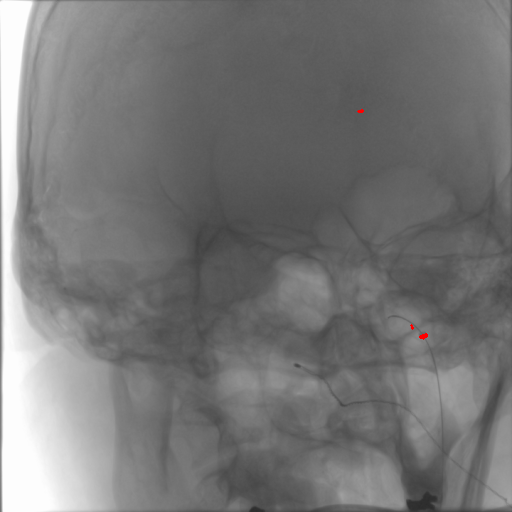

In [ ]:
afficher('suivi_pointe_guidewire/animation.gif')

[Guidewire rouge et microcathéter vert dans le masque à référence fixe](results/fusion_outils/)

### 3.2 Cumuler les positions détectées

Nous prenons l’union du masque courant $D_k$ et du cumul précédent : $C_k = C_{k-1} \cup D_k$. Le cumul, initialement vide, garde ainsi la trace de toutes les nouvelles portions détectées. Le script `test_cumul_guidewire.py` produit les masques cumulés et leur superposition sur la radiographie.


### 3.3 Évaluer la trajectoire cumulée du guidewire

Nous comparons le cumul détecté à l’union des annotations **`GuideWire` dilatées** de 211 à l’image courante. Les deux masques couvrent le même intervalle. Le TIFF trace le guidewire entier à chaque image, ce qui permet de comparer les trajectoires cumulées. Le tracé ne donne pas une position de pointe séparée pour chaque image.

| Image | SAD (pixels) | MSE | PSNR (dB) |
|---:|---:|---:|---:|
| 211 | 251 | 0,000957 | 30,19 |
| 221 | 410 | 0,001564 | 28,06 |
| 231 | 694 | 0,002647 | 25,77 |
| 241 | 977 | 0,003727 | 24,29 |
| 251 | 1 240 | 0,004730 | 23,25 |
| 261 | 1 822 | 0,006950 | 21,58 |
| 271 | 2 284 | 0,008713 | 20,60 |
| 281 | 2 520 | 0,009613 | 20,17 |
| 291 | 2 824 | 0,010773 | 19,68 |

| Mesure | Moyenne | Écart-type |
|---|---:|---:|
| SAD | 1 446,9 | 896,0 |
| MSE | 0,005519 | 0,003418 |
| PSNR (dB) | 23,73 | 3,47 |

Les coupures et les détections isolées visibles sur la planche contribuent aux écarts. [Scores de la trajectoire cumulée](results/cumul_pointe_guidewire/reference_guidewire_cumulee/scores.csv)

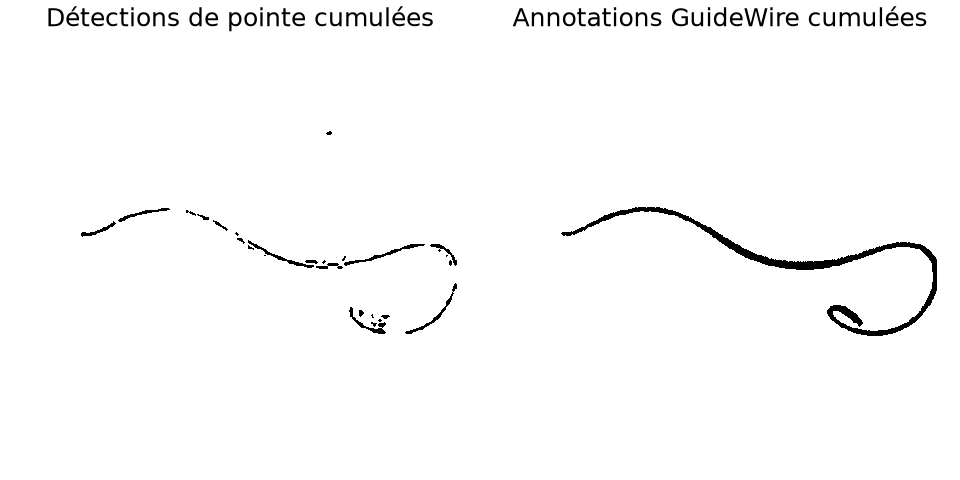

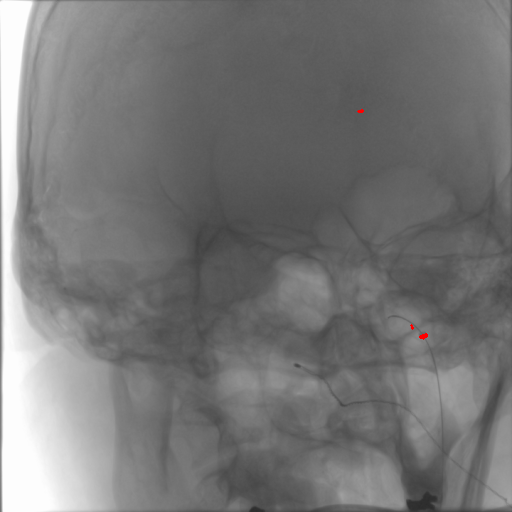

In [ ]:
afficher('cumul_pointe_guidewire/reference_guidewire_cumulee/comparaison_291.png')
afficher('cumul_pointe_guidewire/trajectoire.gif')

## Conclusion

La chaîne de soustraction, filtrage et morphologie produit un masque des changements visibles. La coupe choisie à partir des TIFF attribue la zone haute au guidewire et la zone basse au microcathéter. Les trois zones d’exclusion retirent le bord supérieur gauche, la bande horizontale du bas et la détection parasite qui longe le bord inférieur droit. Les superpositions montrent aussi les structures du fond qui subsistent hors de ces zones. La référence fixe contient déjà une grande partie du microcathéter, ce qui réduit sa réponse à la soustraction.

Les différences successives et le cumul montrent la trajectoire détectée du guidewire. Le cumul conserve aussi les détections isolées et laisse des coupures dans les portions peu visibles. La position de la ligne de séparation dépend du cadrage de cette séquence.

### Reproduire les exports

Depuis la racine du projet, avec l’environnement Python du TP :

```bash
./.venv/bin/python main.py
./.venv/bin/python comparer_filtres.py
./.venv/bin/python test_aire_composantes.py
./.venv/bin/python validation_par_outil.py
./.venv/bin/python test_cumul_guidewire.py
```

Les cellules du notebook relisent les fichiers de `results/`. Les images intégrées sont visibles à l’ouverture.